In [ ]:
import pandas as pd

leads = pd.read_csv(".../olist_marketing_qualified_leads_dataset.csv",
                    parse_dates=["first_contact_date"])
deals = pd.read_csv(".../olist_closed_deals_dataset.csv",
                    parse_dates=["won_date"])

print(leads.shape, deals.shape)

(8000, 4) (842, 14)


In [2]:
# Confirm keys are clean before joining
print("Lead IDs unique:", leads.mql_id.is_unique)
print("Deal IDs unique:", deals.mql_id.is_unique)
print("Deals without a matching lead:", (~deals.mql_id.isin(leads.mql_id)).sum())

# Evidence for dropping columns (keep this output in the notebook)
drop_cols = ["has_company", "has_gtin", "average_stock",
             "declared_product_catalog_size", "declared_monthly_revenue"]
print((deals[drop_cols].isna().mean() * 100).round(1))
print("declared_monthly_revenue == 0:",
      round((deals.declared_monthly_revenue == 0).mean() * 100, 1), "%")

# Drop them (reason: >90% null or zero; only collected from July 2018)
deals = deals.drop(columns=drop_cols)

Lead IDs unique: True
Deal IDs unique: True
Deals without a matching lead: 0
has_company                      92.5
has_gtin                         92.4
average_stock                    92.2
declared_product_catalog_size    91.8
declared_monthly_revenue          0.0
dtype: float64
declared_monthly_revenue == 0: 94.7 %


In [3]:
# Treat missing origin as 'unknown' (both mean "not recorded")
leads["origin"] = leads["origin"].fillna("unknown")

# Cohort: leads first contacted Jan-May 2018
cohort = leads[(leads.first_contact_date >= "2018-01-01") &
               (leads.first_contact_date <= "2018-05-31")].copy()

print("Cohort size:", len(cohort))
print(cohort.origin.value_counts())

Cohort size: 5998
origin
organic_search       1736
paid_search          1182
social               1051
unknown               861
direct_traffic        380
email                 347
referral              211
other                 114
display                75
other_publicities      41
Name: count, dtype: int64


In [ ]:
df = cohort.merge(deals, on="mql_id", how="left", indicator=True)
df["won"] = df["_merge"] == "both"
df = df.drop(columns="_merge")

# Sales cycle in whole days (successfully closed deals only)
df["cycle_days"] = (df["won_date"].dt.normalize()
                    - df["first_contact_date"]).dt.days

# Flag the data error: won before first contact
df["cycle_invalid"] = df["cycle_days"] < 0
print("Won leads:", df.won.sum(), "| Conversion:", round(df.won.mean() * 100, 1), "%")
print("Negative cycles:", df.cycle_invalid.sum())

df.to_csv(".../funnel_clean.csv", index=False)

Won leads: 781 | Conversion: 13.0 %
Negative cycles: 1


In [ ]:
# install matplotlib if not already installed
%pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/Users/Ciel/Portfolio Artifacts/Project 2/funnel_clean.csv",
                 parse_dates=["first_contact_date", "won_date"])
print(df.shape, "| overall conversion:", round(df.won.mean()*100, 1), "%")

(5998, 15) | overall conversion: 13.0 %


In [ ]:
# install statsmodels if not already installed
%pip install statsmodels


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
# Conversion by origin, with uncertainty
from statsmodels.stats.proportion import proportion_confint  # pip install statsmodels

by_origin = (df.groupby("origin").won
               .agg(leads="size", won="sum").reset_index())
by_origin["conv_pct"] = by_origin.won / by_origin.leads * 100
lo, hi = proportion_confint(by_origin.won, by_origin.leads, method="wilson")
by_origin["ci_low"], by_origin["ci_high"] = lo*100, hi*100

# 'unknown' reported separately, not ranked as a channel
channels = (by_origin[by_origin.origin != "unknown"]
            .sort_values("conv_pct", ascending=False))
print(channels.round(1))
print(by_origin[by_origin.origin == "unknown"].round(1))

              origin  leads  won  conv_pct  ci_low  ci_high
6        paid_search   1182  175      14.8    12.9     16.9
3     organic_search   1736  255      14.7    13.1     16.4
0     direct_traffic    380   54      14.2    11.1     18.1
7           referral    211   24      11.4     7.8     16.4
5  other_publicities     41    3       7.3     2.5     19.4
1            display     75    5       6.7     2.9     14.7
8             social   1051   66       6.3     5.0      7.9
2              email    347   14       4.0     2.4      6.7
4              other    114    4       3.5     1.4      8.7
    origin  leads  won  conv_pct  ci_low  ci_high
9  unknown    861  181      21.0    18.4     23.9


In [9]:
# Sales Cycle 
df[df.won & ~df.cycle_invalid].groupby("origin").cycle_days.describe()

,count,mean,std,min,25%,50%,75%,max
origin,,,,,,,,
direct_traffic,54.0,26.018519,39.519515,0.0,4.25,9.5,27.25,163.0
display,5.0,11.600000,9.449868,0.0,7.00,10.0,16.00,25.0
email,14.0,39.785714,57.054870,1.0,8.50,19.5,34.50,210.0
organic_search,254.0,40.503937,59.301850,0.0,5.00,13.0,46.75,306.0
other,4.0,15.250000,18.518009,1.0,4.00,9.0,20.25,42.0
other_publicities,3.0,39.333333,7.505553,35.0,35.00,35.0,41.50,48.0
paid_search,175.0,39.811429,58.569478,0.0,4.50,13.0,48.50,260.0
referral,24.0,32.541667,39.382162,0.0,5.00,18.5,35.25,132.0
social,66.0,44.727273,49.040500,1.0,9.75,23.0,64.50,204.0


In [10]:
# Sales cycle by channel (won deals only, valid cycles)
won = df[df.won & ~df.cycle_invalid].copy()

MIN_DEALS = 20   # channels with fewer won deals are too small to compare
counts = won.origin.value_counts()
keep = counts[counts >= MIN_DEALS].index.drop("unknown", errors="ignore")
w = won[won.origin.isin(keep)]

# Summary table: median, spread, and share closed within 14/30/60 days
summary = w.groupby("origin").cycle_days.agg(
    deals="size",
    median="median",
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
)
for d in (14, 30, 60):
    summary[f"within_{d}d_%"] = (w.groupby("origin").cycle_days
                                   .apply(lambda s: (s <= d).mean() * 100))
summary = summary.sort_values("median")
print(summary.round(1))

                deals  median  p25   p75  within_14d_%  within_30d_%  \
origin                                                                 
direct_traffic     54     9.5  4.2  27.2          66.7          75.9   
organic_search    254    13.0  5.0  46.8          53.1          68.9   
paid_search       175    13.0  4.5  48.5          53.1          70.3   
referral           24    18.5  5.0  35.2          50.0          62.5   
social             66    23.0  9.8  64.5          33.3          59.1   

                within_60d_%  
origin                        
direct_traffic          87.0  
organic_search          78.7  
paid_search             78.3  
referral                83.3  
social                  74.2  


In [11]:
# groups the Jan - May 2018 leads by landing_page_id,
# counts the leads per page and how many became sellers, calculates each page’s conversion rate
lp = (df.groupby("landing_page_id").won
        .agg(leads="size", won="sum").reset_index())
lp["conv_pct"] = lp.won / lp.leads * 100
big = lp[lp.leads >= 30].sort_values("conv_pct", ascending=False)
print(len(lp), "pages total;", len(big), "with 30+ leads")
print(big.round(1).to_string(index=False))

407 pages total; 28 with 30+ leads
                 landing_page_id  leads  won  conv_pct
30077c17f2ec5010a82e37ad8925b95f     39    9      23.1
22c29808c4f815213303f8933030604c    726  167      23.0
b76ef37428e6799c421989521c0e5077    751  163      21.7
40dec9f3d5259a3d2dbcdab2114fae47    297   64      21.5
7fa6214d82e911d070f51ef79381b956     49   10      20.4
d83b0d0e48c8447d1d5507a44027a955     32    6      18.8
b48ec5f3b04e9068441002a19df93c6c     35    6      17.1
ce1a65abd0973638f1c887a6efcfa82d    346   56      16.2
0218f6be0b76aca72ab4d00ee9e8cf10     41    6      14.6
35c9b150ab36fe584c1f24fd458c453a     59    8      13.6
b6885f18d203a61176418c1fb3764815     52    7      13.5
1ceb590cd1e00c7ee95220971f82693d     71    9      12.7
241f79c7a8fe0270f4fb79fcbbcd17ad     79   10      12.7
a7982125ff7aa3b2054c6e44f9d28522    132   15      11.4
f017be4dbf86243af5c1ebed0cff36a2    224   20       8.9
88740e65d5d6b056e0cda098e1ea6313    306   26       8.5
9fa37f5177115156b1814ffc237402

In [12]:
# Which origins feed the top and bottom pages?
top_pages = ["22c29808c4f815213303f8933030604c",
             "b76ef37428e6799c421989521c0e5077",
             "40dec9f3d5259a3d2dbcdab2114fae47",
             "58326e62183c14b0c03085c33b9fdc44",
             "88740e65d5d6b056e0cda098e1ea6313",
             "e492ee5eaf1697716985cc6f33f9cd9b"]
sub = df[df.landing_page_id.isin(top_pages)]
mix = pd.crosstab(sub.landing_page_id.str[:8], sub.origin, normalize="index") * 100
print(mix.round(0))

origin           direct_traffic  display  email  organic_search  other  \
landing_page_id                                                          
22c29808                   12.0      0.0    1.0            57.0    1.0   
40dec9f3                    1.0      0.0    2.0            17.0    0.0   
58326e62                    1.0      0.0    0.0             2.0    0.0   
88740e65                    1.0      0.0    0.0             1.0    1.0   
b76ef374                    3.0      0.0    0.0            14.0    0.0   
e492ee5e                    9.0      1.0   12.0            40.0    6.0   

origin           other_publicities  paid_search  referral  social  unknown  
landing_page_id                                                             
22c29808                       1.0         15.0       6.0     3.0      4.0  
40dec9f3                       1.0         73.0       3.0     1.0      2.0  
58326e62                       0.0          0.0       1.0    94.0      1.0  
88740e65              

In [13]:
social = df[df.origin == "social"].copy()
bad_pages = ["58326e62183c14b0c03085c33b9fdc44",
             "88740e65d5d6b056e0cda098e1ea6313"]
social["page_group"] = social.landing_page_id.isin(bad_pages).map(
    {True: "the two social pages", False: "other pages"})
print(social.groupby("page_group").won.agg(leads="size", won="sum", conv="mean").round(3))

                      leads  won   conv
page_group                             
other pages             302   17  0.056
the two social pages    749   49  0.065


In [14]:
# segment section
won = df[df.won & ~df.cycle_invalid]
for col in ["business_segment", "lead_type"]:
    t = (won.groupby(col).cycle_days
            .agg(deals="size", median="median").sort_values("deals", ascending=False))
    print(t.head(10), "\n")

                                 deals  median
business_segment                              
home_decor                          96    10.5
health_beauty                       88    12.0
car_accessories                     70    12.0
household_utilities                 62     9.5
construction_tools_house_garden     62    10.0
audio_video_electronics             60    18.5
computers                           31    13.0
pet                                 28    12.0
food_supplement                     27    19.0
food_drink                          26    16.0 

                 deals  median
lead_type                     
online_medium      317    11.0
industry           115    14.0
online_big         114    12.0
offline             96    14.5
online_small        66    11.5
online_beginner     51    12.0
online_top          13     5.0
other                3   260.0 



In [15]:
won = df[df.won & ~df.cycle_invalid]
for col in ["business_segment", "lead_type"]:
    t = (won.groupby(col).cycle_days.agg(
            deals="size", median="median",
            p25=lambda s: s.quantile(0.25),
            p75=lambda s: s.quantile(0.75)))
    print(t[t.deals >= 25].sort_values("deals", ascending=False).round(1), "\n")

                                 deals  median  p25   p75
business_segment                                         
home_decor                          96    10.5  6.0  25.0
health_beauty                       88    12.0  6.0  35.0
car_accessories                     70    12.0  5.0  33.0
construction_tools_house_garden     62    10.0  4.0  37.8
household_utilities                 62     9.5  4.0  27.8
audio_video_electronics             60    18.5  5.5  96.5
computers                           31    13.0  9.0  32.5
pet                                 28    12.0  5.0  23.2
food_supplement                     27    19.0  8.5  53.0
food_drink                          26    16.0  8.0  33.2
sports_leisure                      25     8.0  4.0  36.0 

                 deals  median  p25   p75
lead_type                                
online_medium      317    11.0  4.0  38.0
industry           115    14.0  7.0  42.5
online_big         114    12.0  4.2  32.8
offline             96    14.5  6.

In [16]:
import os, matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint
os.makedirs("../figures", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"../figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

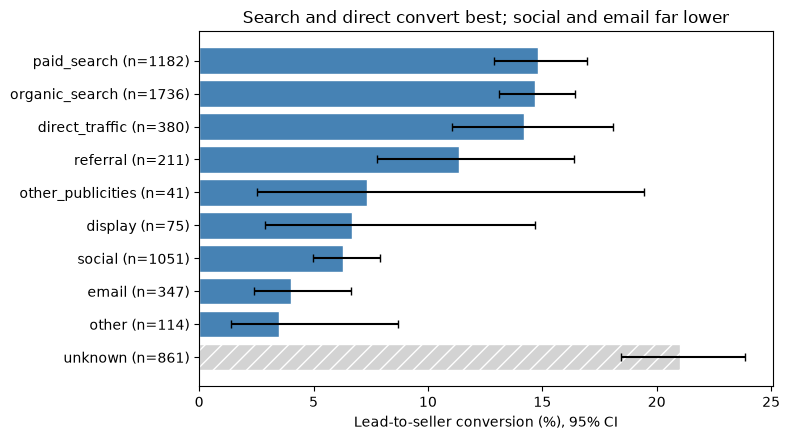

In [17]:
# chart 1: coversion by origin, with confidence intervals
g = df.groupby("origin").won.agg(leads="size", won="sum").reset_index()
g["conv"] = g.won / g.leads * 100
lo, hi = proportion_confint(g.won, g.leads, method="wilson")
g["lo"], g["hi"] = lo * 100, hi * 100
g["is_unknown"] = g.origin == "unknown"
g = g.sort_values(["is_unknown", "conv"], ascending=[True, False])

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, r in enumerate(g.itertuples()):
    ax.barh(i, r.conv, color="lightgray" if r.is_unknown else "steelblue",
            hatch="//" if r.is_unknown else None, edgecolor="white")
    ax.errorbar(r.conv, i, xerr=[[r.conv - r.lo], [r.hi - r.conv]],
                color="black", capsize=3)
ax.set_yticks(range(len(g)))
ax.set_yticklabels([f"{r.origin} (n={r.leads})" for r in g.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("Lead-to-seller conversion (%), 95% CI")
ax.set_title("Search and direct convert best; social and email far lower")
save("1_conversion_by_origin")

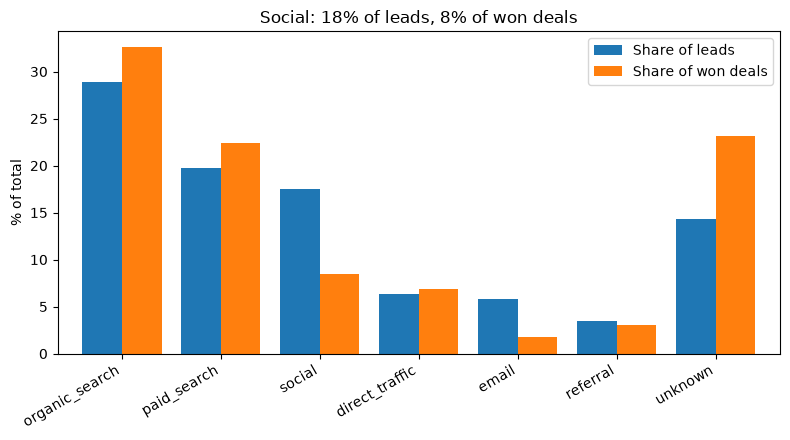

In [18]:
# chart 2: share of leads vs share of won deals
main = ["organic_search", "paid_search", "social", "direct_traffic",
        "email", "referral", "unknown"]
t = df.groupby("origin").agg(leads=("won", "size"), won=("won", "sum")).loc[main]
t["lead_share"] = t.leads / len(df) * 100
t["win_share"] = t.won / df.won.sum() * 100

ax = t[["lead_share", "win_share"]].plot.bar(figsize=(8, 4.5), width=0.8)
ax.set_ylabel("% of total")
ax.set_xlabel("")
ax.legend(["Share of leads", "Share of won deals"])
ax.set_title("Social: 18% of leads, 8% of won deals")
plt.xticks(rotation=30, ha="right")
save("2_lead_share_vs_win_share")

/var/folders/9q/c4p4qm7n0cjdymf33f987yhr0000gp/T/ipykernel_63362/2243906487.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([won.loc[won.origin == o, "cycle_days"] for o in order],


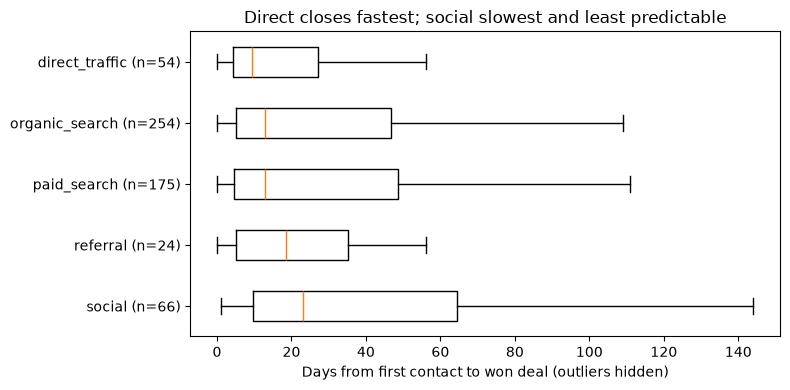

In [19]:
# chart 3: sales cycle boxplot
won = df[df.won & ~df.cycle_invalid]
counts = won.origin.value_counts()
keep = [o for o in counts[counts >= 20].index if o != "unknown"]
order = won[won.origin.isin(keep)].groupby("origin").cycle_days.median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([won.loc[won.origin == o, "cycle_days"] for o in order],
           vert=False, showfliers=False)
ax.set_yticklabels([f"{o} (n={counts[o]})" for o in order])
ax.invert_yaxis()
ax.set_xlabel("Days from first contact to won deal (outliers hidden)")
ax.set_title("Direct closes fastest; social slowest and least predictable")
save("3_sales_cycle_by_origin")

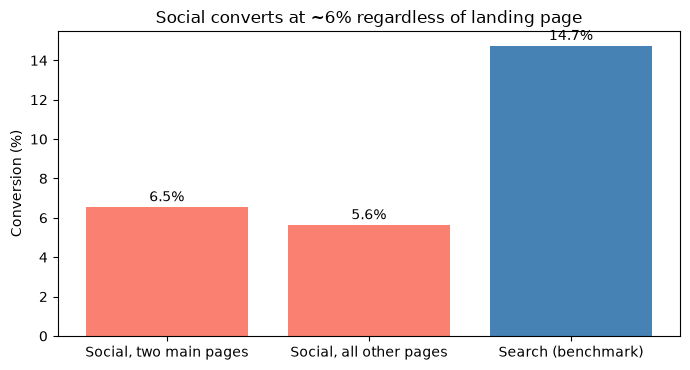

In [20]:
# chart 4: Social converts poorly on every landing page
bad = ["58326e62183c14b0c03085c33b9fdc44", "88740e65d5d6b056e0cda098e1ea6313"]
social = df[df.origin == "social"]
on_bad = social[social.landing_page_id.isin(bad)].won.mean() * 100
on_other = social[~social.landing_page_id.isin(bad)].won.mean() * 100
search = df[df.origin.isin(["paid_search", "organic_search"])].won.mean() * 100

fig, ax = plt.subplots(figsize=(7, 3.8))
labels = ["Social, two main pages", "Social, all other pages", "Search (benchmark)"]
vals = [on_bad, on_other, search]
ax.bar(labels, vals, color=["salmon", "salmon", "steelblue"])
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center")
ax.set_ylabel("Conversion (%)")
ax.set_title("Social converts at ~6% regardless of landing page")
save("4_social_by_page")